# L4 – Dark Patterns and Web User Behavior

## Experimental Data Analysis

### Obiectivul cercetării

Analiza influenței Dark Patterns asupra comportamentului
utilizatorilor în magazinele online.

Experimentul compară două grupuri:

- Normal – interfață transparentă.
- Dark Patterns – interfață manipulativă.

Indicatori analizați:

- Timpul de rezolvare a sarcinilor.
- Numărul de erori.
- Numărul de clickuri.
- Nivelul de încredere.
- Nivelul de control perceput.

Etapa curentă: validarea tehnică folosind date de test.

In [40]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import mannwhitneyu
from scipy.stats import chi2_contingency
from scipy.stats import fisher_exact

from pathlib import Path

sns.set_theme(style="whitegrid")

print("Bibliotecile au fost importate cu succes!")

Bibliotecile au fost importate cu succes!


In [ ]:
DATA_MODE = "test"

project_root = Path.cwd()

if project_root.name == "analysis":
    project_root = project_root.parent

if DATA_MODE == "real":
    data_path = project_root / "data/test/pilot_test.csv"
else:
    data_path = project_root / "data/participants/results.csv"

df = pd.read_csv(data_path, decimal=",")

print("Dataset incarcat cu succes!")
print("Mod de analiza:", DATA_MODE)
print("Numar de randuri:", df.shape[0])
print("Numar de coloane:", df.shape[1])

df

Dataset incarcat cu succes!
Mod de analiza: test
Numar de randuri: 16
Numar de coloane: 16


,participant_id,group,task1_time,task1_error,task1_clicks,task2_time,task2_error,task2_clicks,task3_time,task3_error,task3_clicks,total_time,total_errors,total_clicks,confidence,control
0,12345678-1234-1234-1234-123456789012,normal,10,0,2,15,0,3,8,0,1,33,0,6,4,5
1,d7d0163c-4aae-42ad-8e12-280683a1567f,normal,"2,69",0,1,"5,17",0,2,"1,53",0,1,"9,39",0,4,4,5
2,fbf0d112-8083-46cf-ba6a-a500046035f2,dark_patterns,"2,43",1,1,"3,5",0,2,"2,98",0,1,"8,91",1,4,3,2
3,758fe558-c2cd-4a21-9f6b-3042a9c6f229,dark_patterns,"1,73",1,1,"3,28",0,2,"3,48",0,1,"8,49",1,4,2,2
4,5a6c2e06-ac8b-49b3-b61b-e0708f1bdad6,normal,"1,71",0,1,"3,03",0,2,"2,4",0,1,"7,14",0,4,5,4
5,5bfeb8df-5c3c-48ff-a473-95f47b0c33ac,normal,"16,57",0,3,"9,4",0,2,"19,82",0,1,"45,79",0,6,4,4
6,6b238fdd-9dd8-494a-824e-d2fd4e95cec7,normal,"18,32",1,2,"15,94",1,2,"4,6",0,1,"38,86",2,5,5,5
7,ae8fd032-f1ab-4c09-a1aa-7212a1a95bce,normal,"12,04",0,1,"19,29",0,3,"6,33",0,1,"37,66",0,5,2,1
8,1d6ac5dd-756d-4ba8-9287-f972b9cdc327,dark_patterns,"5,86",1,1,"9,94",0,2,"4,1",1,1,"19,9",2,4,3,3
9,595164fc-49e7-4330-a839-4971e4dd7481,dark_patterns,"11,51",0,2,"10,96",0,2,"7,96",0,1,"30,43",0,5,4,3


In [13]:
print("Dimensiunea datasetului:")
print(df.shape)

print("\nColoanele datasetului:")
print(df.columns.tolist())

print("\nInformatii despre dataset:")
df.info()

Dimensiunea datasetului:
(6, 16)

Coloanele datasetului:
['participant_id', 'group', 'task1_time', 'task1_error', 'task1_clicks', 'task2_time', 'task2_error', 'task2_clicks', 'task3_time', 'task3_error', 'task3_clicks', 'total_time', 'total_errors', 'total_clicks', 'confidence', 'control']

Informatii despre dataset:
<class 'pandas.DataFrame'>
RangeIndex: 6 entries, 0 to 5
Data columns (total 16 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   participant_id  6 non-null      str  
 1   group           6 non-null      str  
 2   task1_time      6 non-null      str  
 3   task1_error     6 non-null      int64
 4   task1_clicks    6 non-null      int64
 5   task2_time      6 non-null      str  
 6   task2_error     6 non-null      int64
 7   task2_clicks    6 non-null      int64
 8   task3_time      6 non-null      str  
 9   task3_error     6 non-null      int64
 10  task3_clicks    6 non-null      int64
 11  total_time      6 non-null 

In [42]:
print("Numarul de inregistrari pe grup:")

group_counts = df["group"].value_counts()

print(group_counts)

print("\nDistributia procentuala:")

print(
    df["group"].value_counts(normalize=True) * 100
)

Numarul de inregistrari pe grup:
group
normal           8
dark_patterns    8
Name: count, dtype: int64

Distributia procentuala:
group
normal           50.0
dark_patterns    50.0
Name: proportion, dtype: float64


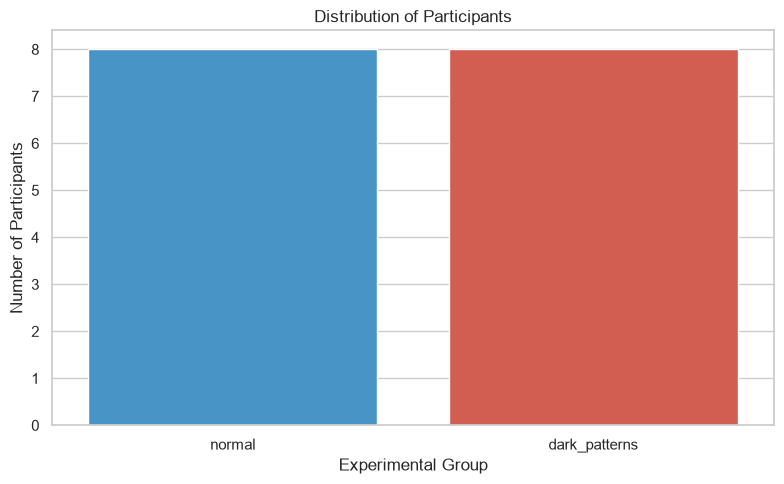

In [43]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="group",
    hue="group",
    order=["normal", "dark_patterns"],
    palette=["#3498db", "#e74c3c"],
    legend=False
)

plt.title("Distribution of Participants")
plt.xlabel("Experimental Group")
plt.ylabel("Number of Participants")

plt.tight_layout()
plt.show()

In [44]:
print("Valori lipsa pentru fiecare coloana:")

print(df.isnull().sum())

print("\nTotal valori lipsa:")
print(df.isnull().sum().sum())

Valori lipsa pentru fiecare coloana:
participant_id    0
group             0
task1_time        0
task1_error       0
task1_clicks      0
task2_time        0
task2_error       0
task2_clicks      0
task3_time        0
task3_error       0
task3_clicks      0
total_time        0
total_errors      0
total_clicks      0
confidence        0
control           0
dtype: int64

Total valori lipsa:
0


In [17]:
print("Numar de randuri duplicate:")
print(df.duplicated().sum())

print("\nNumar de ID-uri duplicate:")
print(df["participant_id"].duplicated().sum())

Numar de randuri duplicate:
0

Numar de ID-uri duplicate:
0


In [ ]:
df_clean = df.copy()

initial_rows = len(df_clean)

# Convertirea coloanelor numerice
numeric_columns = [
    col for col in df_clean.columns
    if col not in ["participant_id", "group"]
]

for col in numeric_columns:
    df_clean[col] = pd.to_numeric(
        df_clean[col].astype(str)
        .str.strip()
        .str.replace(",", ".", regex=False),
        errors="coerce"
    )
    
# Eliminarea valorilor lipsa
df_clean = df_clean.dropna()

# Eliminarea duplicatelor
df_clean = df_clean.drop_duplicates(
    subset="participant_id"
)

# Validarea grupurilor experimentale
df_clean = df_clean[
    df_clean["group"].isin(["normal", "dark_patterns"])
]

# Validarea valorilor numerice
df_clean = df_clean[
    (df_clean[numeric_columns] >= 0).all(axis=1)
]

# Validarea raspunsurilor la chestionar
df_clean = df_clean[
    df_clean["confidence"].isin([1, 2, 3, 4, 5]) &
    df_clean["control"].isin([1, 2, 3, 4, 5])
]

print("Inregistrari initiale:", initial_rows)
print("Inregistrari valide:", len(df_clean))
print("Inregistrari eliminate:", initial_rows - len(df_clean))

display(df_clean)

Inregistrari initiale: 6
Inregistrari valide: 1
Inregistrari eliminate: 5


,participant_id,group,task1_time,task1_error,task1_clicks,task2_time,task2_error,task2_clicks,task3_time,task3_error,task3_clicks,total_time,total_errors,total_clicks,confidence,control
0,12345678-1234-1234-1234-123456789012,normal,10.0,0,2,15.0,0,3,8.0,0,1,33.0,0,6,4,5


In [19]:
valid_time = np.isclose(
    df_clean["total_time"],
    df_clean["task1_time"] +
    df_clean["task2_time"] +
    df_clean["task3_time"],
    atol=0.02,
    rtol=0
)

valid_errors = (
    df_clean["total_errors"] ==
    df_clean["task1_error"] +
    df_clean["task2_error"] +
    df_clean["task3_error"]
)

valid_clicks = (
    df_clean["total_clicks"] ==
    df_clean["task1_clicks"] +
    df_clean["task2_clicks"] +
    df_clean["task3_clicks"]
)

valid_error_values = df_clean[
    ["task1_error", "task2_error", "task3_error"]
].isin([0, 1]).all(axis=1)

click_columns = [
    "task1_clicks", "task2_clicks", "task3_clicks"
]

valid_click_values = (
    df_clean[click_columns] % 1 == 0
).all(axis=1)

print("Timpi corecti:", valid_time.all())
print("Total erori corect:", valid_errors.all())
print("Total clickuri corect:", valid_clicks.all())
print("Valori erori valide:", valid_error_values.all())
print("Valori clickuri valide:", valid_click_values.all())

valid_rows = (
    valid_time &
    valid_errors &
    valid_clicks &
    valid_error_values &
    valid_click_values
)

print("Inregistrari inconsistente:", (~valid_rows).sum())

df_clean = df_clean.loc[valid_rows].copy()

Timpi corecti: True
Total erori corect: True
Total clickuri corect: True
Valori erori valide: True
Valori clickuri valide: True
Inregistrari inconsistente: 0


In [20]:
output_path = data_path.parent / "cleaned_results.csv"

df_clean.to_csv(output_path, index=False)

print("Datasetul curatat a fost salvat!")
print("Locatie:", output_path)
print("Inregistrari finale:", len(df_clean))

Datasetul curatat a fost salvat!
Locatie: /Users/vladtotelecan/ProiectDecercetareDarkPatterns/data/test/cleaned_results.csv
Inregistrari finale: 1


In [48]:
print("Valori lipsa:")
print(df.isnull().sum())

print("\nID-uri duplicate:")
print(df["participant_id"].duplicated().sum())

print("\nGrupuri experimentale:")
print(df["group"].value_counts())

print("\nTipurile coloanelor:")
print(df.dtypes)

print("\nValorile confidence:")
print(df["confidence"].value_counts())

print("\nValorile control:")
print(df["control"].value_counts())

print("\nVerificarea conversiei numerice:")

for col in numeric_columns:
    converted = pd.to_numeric(df[col], errors="coerce")
    print(col, "- valori invalide:", converted.isna().sum())

Valori lipsa:
participant_id    0
group             0
task1_time        0
task1_error       0
task1_clicks      0
task2_time        0
task2_error       0
task2_clicks      0
task3_time        0
task3_error       0
task3_clicks      0
total_time        0
total_errors      0
total_clicks      0
confidence        0
control           0
dtype: int64

ID-uri duplicate:
0

Grupuri experimentale:
group
normal           8
dark_patterns    8
Name: count, dtype: int64

Tipurile coloanelor:
participant_id      str
group               str
task1_time          str
task1_error       int64
task1_clicks      int64
task2_time          str
task2_error       int64
task2_clicks      int64
task3_time          str
task3_error       int64
task3_clicks      int64
total_time          str
total_errors      int64
total_clicks      int64
confidence        int64
control           int64
dtype: object

Valorile confidence:
confidence
5    6
4    4
3    3
2    3
Name: count, dtype: int64

Valorile control:
control
5   

In [49]:
print("Inregistrari originale:", len(df))

print("\nVerificarea totalurilor:")

print("Timpi incorecti:", (~valid_time).sum())
print("Erori incorecte:", (~valid_errors).sum())
print("Clickuri incorecte:", (~valid_clicks).sum())
print("Valori erori invalide:", (~valid_error_values).sum())
print("Valori clickuri invalide:", (~valid_click_values).sum())

print("\nInregistrari finale:", len(df_clean))

Inregistrari originale: 16

Verificarea totalurilor:
Timpi incorecti: 0
Erori incorecte: 0
Clickuri incorecte: 0
Valori erori invalide: 0
Valori clickuri invalide: 0

Inregistrari finale: 1


In [47]:
print("Total inregistrari:", len(df))
print("Inregistrari valide:", len(df_clean))
print("Inregistrari eliminate:", len(df) - len(df_clean))

print("\nDistributia pe grupuri:")
print(df_clean["group"].value_counts())

Total inregistrari: 16
Inregistrari valide: 1
Inregistrari eliminate: 15

Distributia pe grupuri:
group
normal    1
Name: count, dtype: int64


In [45]:
print("=== RAPORT VALIDARE DATASET ===")

print("\nTotal inregistrari:", len(df))
print("Inregistrari valide tehnic:", len(df_clean))
print("Inregistrari eliminate:", len(df) - len(df_clean))

print("\nDistributia inainte de curatare:")
print(df["group"].value_counts())

print("\nDistributia dupa curatare:")
print(df_clean["group"].value_counts())

print("\nProcentul inregistrarilor valide:")
print(round(len(df_clean) / len(df) * 100, 2), "%")

print("\nInregistrari eliminate:")
display(df.loc[~df.index.isin(df_clean.index)])

=== RAPORT VALIDARE DATASET ===

Total inregistrari: 16
Inregistrari valide tehnic: 1
Inregistrari eliminate: 15

Distributia inainte de curatare:
group
normal           8
dark_patterns    8
Name: count, dtype: int64

Distributia dupa curatare:
group
normal    1
Name: count, dtype: int64

Procentul inregistrarilor valide:
6.25 %

Inregistrari eliminate:


,participant_id,group,task1_time,task1_error,task1_clicks,task2_time,task2_error,task2_clicks,task3_time,task3_error,task3_clicks,total_time,total_errors,total_clicks,confidence,control
1,d7d0163c-4aae-42ad-8e12-280683a1567f,normal,"2,69",0,1,"5,17",0,2,"1,53",0,1,"9,39",0,4,4,5
2,fbf0d112-8083-46cf-ba6a-a500046035f2,dark_patterns,"2,43",1,1,"3,5",0,2,"2,98",0,1,"8,91",1,4,3,2
3,758fe558-c2cd-4a21-9f6b-3042a9c6f229,dark_patterns,"1,73",1,1,"3,28",0,2,"3,48",0,1,"8,49",1,4,2,2
4,5a6c2e06-ac8b-49b3-b61b-e0708f1bdad6,normal,"1,71",0,1,"3,03",0,2,"2,4",0,1,"7,14",0,4,5,4
5,5bfeb8df-5c3c-48ff-a473-95f47b0c33ac,normal,"16,57",0,3,"9,4",0,2,"19,82",0,1,"45,79",0,6,4,4
6,6b238fdd-9dd8-494a-824e-d2fd4e95cec7,normal,"18,32",1,2,"15,94",1,2,"4,6",0,1,"38,86",2,5,5,5
7,ae8fd032-f1ab-4c09-a1aa-7212a1a95bce,normal,"12,04",0,1,"19,29",0,3,"6,33",0,1,"37,66",0,5,2,1
8,1d6ac5dd-756d-4ba8-9287-f972b9cdc327,dark_patterns,"5,86",1,1,"9,94",0,2,"4,1",1,1,"19,9",2,4,3,3
9,595164fc-49e7-4330-a839-4971e4dd7481,dark_patterns,"11,51",0,2,"10,96",0,2,"7,96",0,1,"30,43",0,5,4,3
10,298917f0-139c-4bc5-a634-737f2fd382a9,normal,"10,72",1,2,"11,95",0,2,"4,2",0,1,"26,87",1,5,5,5


In [21]:
metrics = [
    "total_time",
    "total_errors",
    "total_clicks",
    "confidence",
    "control"
]

df_clean[metrics].describe().round(2)

,total_time,total_errors,total_clicks,confidence,control
count,1.0,1.0,1.0,1.0,1.0
mean,33.0,0.0,6.0,4.0,5.0
std,NaN,NaN,NaN,NaN,NaN
min,33.0,0.0,6.0,4.0,5.0
25%,33.0,0.0,6.0,4.0,5.0
50%,33.0,0.0,6.0,4.0,5.0
75%,33.0,0.0,6.0,4.0,5.0
max,33.0,0.0,6.0,4.0,5.0


In [22]:
group_statistics = df_clean.groupby("group")[metrics].agg(
    ["count", "mean", "median", "std", "min", "max"]
).round(2)

display(group_statistics)

total_time                              total_errors                  \
            count  mean median std   min   max        count mean median std   
group                                                                         
normal          1  33.0   33.0 NaN  33.0  33.0            1  0.0    0.0 NaN   

        ... confidence             control                          
        ...     median std min max   count mean median std min max  
group   ...                                                         
normal  ...        4.0 NaN   4   4       1  5.0    5.0 NaN   5   5  

[1 rows x 30 columns]

In [23]:
group_means = df_clean.groupby("group")[metrics].mean().T

display(group_means.round(2))

group,normal
total_time,33.0
total_errors,0.0
total_clicks,6.0
confidence,4.0
control,5.0


/var/folders/fj/1pcy35m558gc_b3s7b48vwk40000gn/T/ipykernel_34788/95252506.py:3: UserWarning: The palette list has more values (2) than needed (1), which may not be intended.
  sns.boxplot(


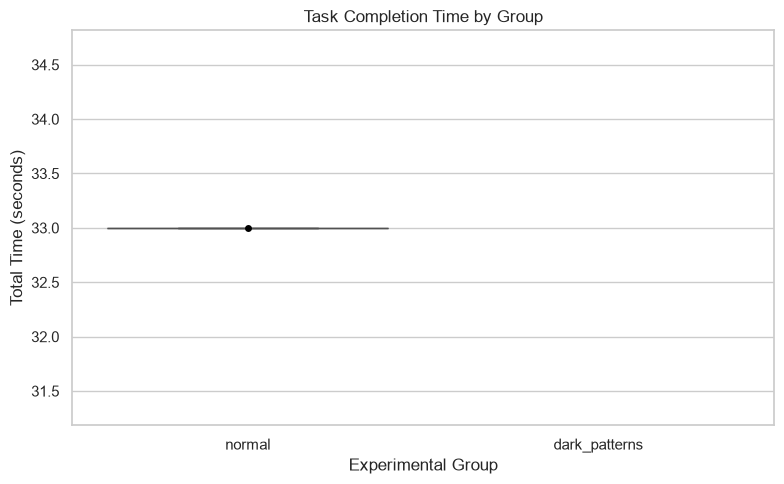

In [24]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df_clean,
    x="group",
    y="total_time",
    hue="group",
    order=["normal", "dark_patterns"],
    palette=["#3498db", "#e74c3c"],
    legend=False
)

sns.stripplot(
    data=df_clean,
    x="group",
    y="total_time",
    order=["normal", "dark_patterns"],
    color="black",
    jitter=True
)

plt.title("Task Completion Time by Group")
plt.xlabel("Experimental Group")
plt.ylabel("Total Time (seconds)")

plt.tight_layout()
plt.show()

/var/folders/fj/1pcy35m558gc_b3s7b48vwk40000gn/T/ipykernel_34788/483038228.py:3: UserWarning: The palette list has more values (2) than needed (1), which may not be intended.
  sns.barplot(


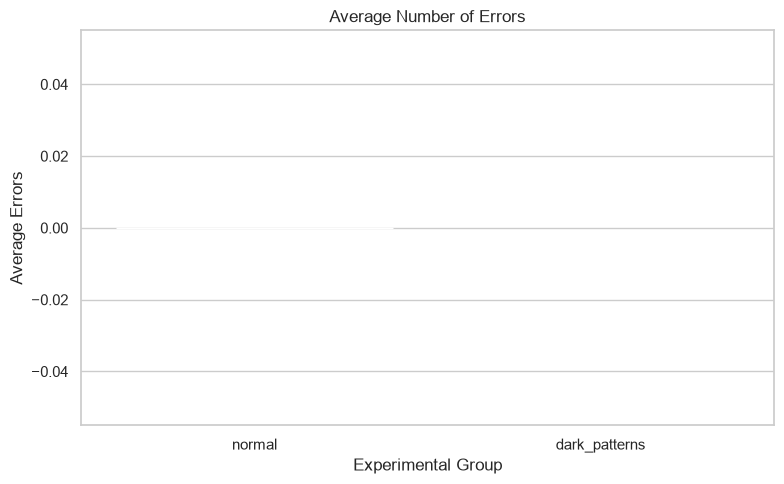

In [25]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=df_clean,
    x="group",
    y="total_errors",
    hue="group",
    order=["normal", "dark_patterns"],
    palette=["#3498db", "#e74c3c"],
    errorbar=None,
    legend=False
)

plt.title("Average Number of Errors")
plt.xlabel("Experimental Group")
plt.ylabel("Average Errors")

plt.tight_layout()
plt.show()

/var/folders/fj/1pcy35m558gc_b3s7b48vwk40000gn/T/ipykernel_34788/2068417253.py:3: UserWarning: The palette list has more values (2) than needed (1), which may not be intended.
  sns.barplot(


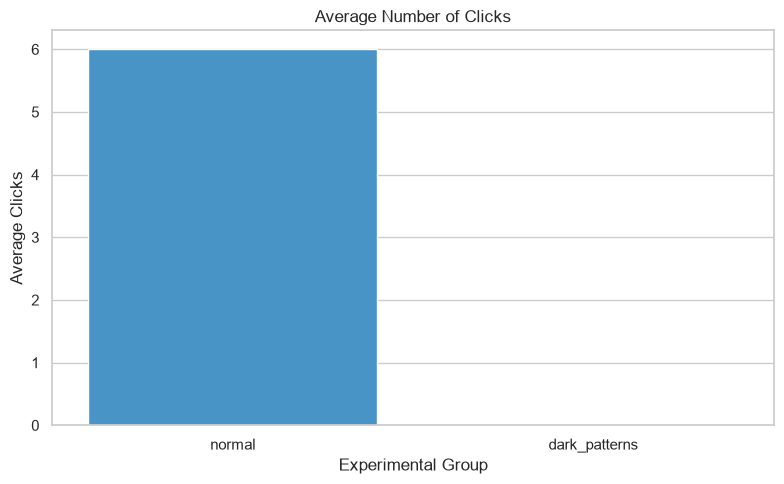

In [26]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=df_clean,
    x="group",
    y="total_clicks",
    hue="group",
    order=["normal", "dark_patterns"],
    palette=["#3498db", "#e74c3c"],
    errorbar=None,
    legend=False
)

plt.title("Average Number of Clicks")
plt.xlabel("Experimental Group")
plt.ylabel("Average Clicks")

plt.tight_layout()
plt.show()

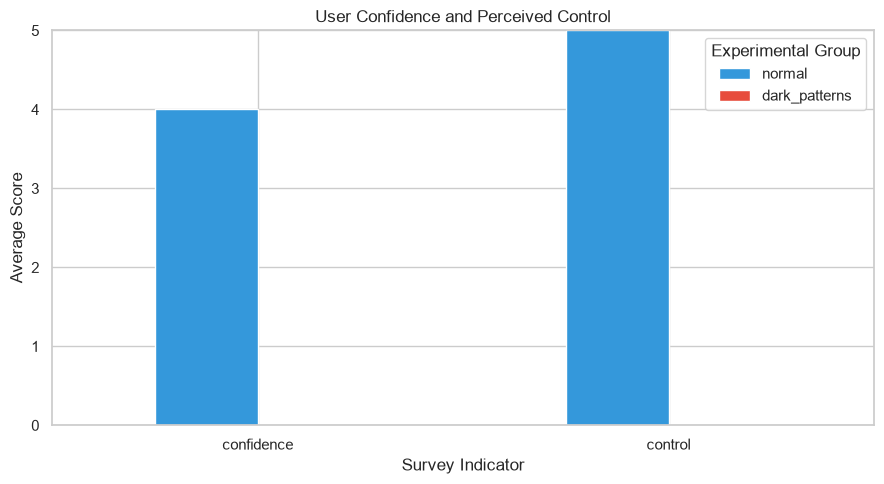

In [27]:
survey_means = df_clean.groupby("group")[
    ["confidence", "control"]
].mean().T

survey_means = survey_means.reindex(
    columns=["normal", "dark_patterns"]
)

survey_means.plot(
    kind="bar",
    figsize=(9, 5),
    color=["#3498db", "#e74c3c"],
    rot=0
)

plt.title("User Confidence and Perceived Control")
plt.xlabel("Survey Indicator")
plt.ylabel("Average Score")
plt.ylim(0, 5)

plt.legend(title="Experimental Group")
plt.tight_layout()
plt.show()

group,normal,dark_patterns
Product Purchase,0.0,NaN
Final Price,0.0,NaN
Subscription Cancellation,0.0,NaN


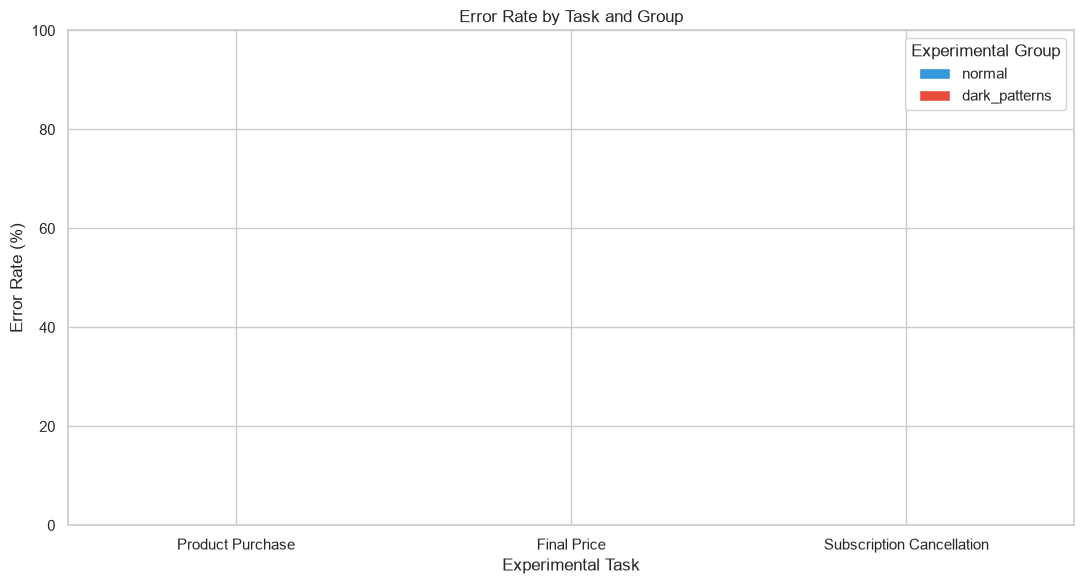

In [28]:
task_errors = df_clean.groupby("group")[
    ["task1_error", "task2_error", "task3_error"]
].mean().T * 100

task_errors.index = [
    "Product Purchase",
    "Final Price",
    "Subscription Cancellation"
]

task_errors = task_errors.reindex(
    columns=["normal", "dark_patterns"]
)

display(task_errors.round(2))

task_errors.plot(
    kind="bar",
    figsize=(11, 6),
    color=["#3498db", "#e74c3c"],
    rot=0
)

plt.title("Error Rate by Task and Group")
plt.xlabel("Experimental Task")
plt.ylabel("Error Rate (%)")
plt.ylim(0, 100)

plt.legend(title="Experimental Group")
plt.tight_layout()
plt.show()

In [29]:
normal_group = df_clean[
    df_clean["group"] == "normal"
]

dark_group = df_clean[
    df_clean["group"] == "dark_patterns"
]

print("Grupul Normal:", len(normal_group))
print("Grupul Dark Patterns:", len(dark_group))

Grupul Normal: 1
Grupul Dark Patterns: 0


In [30]:
statistic, p_value = mannwhitneyu(
    normal_group["total_time"],
    dark_group["total_time"],
    alternative="two-sided",
    method="auto"
)

print("Mann-Whitney U:", statistic)
print("P-value:", round(p_value, 4))

alpha = 0.05

if p_value < alpha:
    print("Diferenta este semnificativa statistic.")
else:
    print("Diferenta nu este semnificativa statistic.")

Mann-Whitney U: nan
P-value: nan
Diferenta nu este semnificativa statistic.


/var/folders/fj/1pcy35m558gc_b3s7b48vwk40000gn/T/ipykernel_34788/698351477.py:1: SmallSampleWarning: One or more sample arguments is too small; all returned values will be NaN. See documentation for sample size requirements.
  statistic, p_value = mannwhitneyu(


In [31]:
statistical_results = []

for metric in metrics:

    statistic, p_value = mannwhitneyu(
        normal_group[metric],
        dark_group[metric],
        alternative="two-sided",
        method="auto"
    )

    statistical_results.append({
        "Metric": metric,
        "Normal Mean": normal_group[metric].mean(),
        "Dark Patterns Mean": dark_group[metric].mean(),
        "Normal Median": normal_group[metric].median(),
        "Dark Patterns Median": dark_group[metric].median(),
        "U Statistic": statistic,
        "P-value": p_value,
        "Significant": p_value < 0.05
    })

stats_df = pd.DataFrame(statistical_results)

display(stats_df.round(4))

/var/folders/fj/1pcy35m558gc_b3s7b48vwk40000gn/T/ipykernel_34788/3075216580.py:5: SmallSampleWarning: One or more sample arguments is too small; all returned values will be NaN. See documentation for sample size requirements.
  statistic, p_value = mannwhitneyu(
/var/folders/fj/1pcy35m558gc_b3s7b48vwk40000gn/T/ipykernel_34788/3075216580.py:5: SmallSampleWarning: One or more sample arguments is too small; all returned values will be NaN. See documentation for sample size requirements.
  statistic, p_value = mannwhitneyu(
/var/folders/fj/1pcy35m558gc_b3s7b48vwk40000gn/T/ipykernel_34788/3075216580.py:5: SmallSampleWarning: One or more sample arguments is too small; all returned values will be NaN. See documentation for sample size requirements.
  statistic, p_value = mannwhitneyu(
/var/folders/fj/1pcy35m558gc_b3s7b48vwk40000gn/T/ipykernel_34788/3075216580.py:5: SmallSampleWarning: One or more sample arguments is too small; all returned values will be NaN. See documentation for sample size

,Metric,Normal Mean,Dark Patterns Mean,Normal Median,Dark Patterns Median,U Statistic,P-value,Significant
0,total_time,33.0,NaN,33.0,NaN,NaN,NaN,False
1,total_errors,0.0,NaN,0.0,NaN,NaN,NaN,False
2,total_clicks,6.0,NaN,6.0,NaN,NaN,NaN,False
3,confidence,4.0,NaN,4.0,NaN,NaN,NaN,False
4,control,5.0,NaN,5.0,NaN,NaN,NaN,False


In [32]:
from statsmodels.stats.multitest import multipletests

stats_df["Adjusted P-value"] = multipletests(
    stats_df["P-value"],
    alpha=0.05,
    method="holm"
)[1]

stats_df["Adjusted Significant"] = (
    stats_df["Adjusted P-value"] < 0.05
)

display(stats_df.round(4))

,Metric,Normal Mean,Dark Patterns Mean,Normal Median,Dark Patterns Median,U Statistic,P-value,Significant,Adjusted P-value,Adjusted Significant
0,total_time,33.0,NaN,33.0,NaN,NaN,NaN,False,NaN,False
1,total_errors,0.0,NaN,0.0,NaN,NaN,NaN,False,NaN,False
2,total_clicks,6.0,NaN,6.0,NaN,NaN,NaN,False,NaN,False
3,confidence,4.0,NaN,4.0,NaN,NaN,NaN,False,NaN,False
4,control,5.0,NaN,5.0,NaN,NaN,NaN,False,NaN,False


In [33]:
n_normal = len(normal_group)
n_dark = len(dark_group)

stats_df["Effect Size"] = (
    1 - (
        2 * stats_df["U Statistic"] /
        (n_normal * n_dark)
    )
)

def interpret_effect(value):

    value = abs(value)

    if value < 0.1:
        return "Negligible"
    elif value < 0.3:
        return "Small"
    elif value < 0.5:
        return "Medium"
    else:
        return "Large"

stats_df["Effect Magnitude"] = (
    stats_df["Effect Size"].apply(interpret_effect)
)

display(stats_df.round(4))

,Metric,Normal Mean,Dark Patterns Mean,Normal Median,Dark Patterns Median,U Statistic,P-value,Significant,Adjusted P-value,Adjusted Significant,Effect Size,Effect Magnitude
0,total_time,33.0,NaN,33.0,NaN,NaN,NaN,False,NaN,False,NaN,Large
1,total_errors,0.0,NaN,0.0,NaN,NaN,NaN,False,NaN,False,NaN,Large
2,total_clicks,6.0,NaN,6.0,NaN,NaN,NaN,False,NaN,False,NaN,Large
3,confidence,4.0,NaN,4.0,NaN,NaN,NaN,False,NaN,False,NaN,Large
4,control,5.0,NaN,5.0,NaN,NaN,NaN,False,NaN,False,NaN,Large


In [34]:
fisher_results = []

for task in ["task1_error", "task2_error", "task3_error"]:

    contingency_table = pd.crosstab(
        df_clean["group"],
        df_clean[task]
    ).reindex(
        index=["normal", "dark_patterns"],
        columns=[0, 1],
        fill_value=0
    )

    odds_ratio, p_value = fisher_exact(
        contingency_table,
        alternative="two-sided"
    )

    fisher_results.append({
        "Task": task,
        "Normal Error Rate (%)": normal_group[task].mean() * 100,
        "Dark Patterns Error Rate (%)": dark_group[task].mean() * 100,
        "Odds Ratio": odds_ratio,
        "P-value": p_value,
        "Significant": p_value < 0.05
    })

fisher_df = pd.DataFrame(fisher_results)

fisher_df["Adjusted P-value"] = multipletests(
    fisher_df["P-value"],
    method="holm"
)[1]

fisher_df["Adjusted Significant"] = (
    fisher_df["Adjusted P-value"] < 0.05
)

display(fisher_df.round(4))

,Task,Normal Error Rate (%),Dark Patterns Error Rate (%),Odds Ratio,P-value,Significant,Adjusted P-value,Adjusted Significant
0,task1_error,0.0,NaN,NaN,1.0,False,1.0,False
1,task2_error,0.0,NaN,NaN,1.0,False,1.0,False
2,task3_error,0.0,NaN,NaN,1.0,False,1.0,False


In [35]:
results_folder = project_root / "results" / DATA_MODE

results_folder.mkdir(
    parents=True,
    exist_ok=True
)

stats_df.to_csv(
    results_folder / "mann_whitney_results.csv",
    index=False
)

fisher_df.to_csv(
    results_folder / "fisher_results.csv",
    index=False
)

print("Rezultatele statistice au fost salvate!")
print(results_folder)

Rezultatele statistice au fost salvate!
/Users/vladtotelecan/ProiectDecercetareDarkPatterns/results/test


In [36]:
figures_folder = project_root / "results" / DATA_MODE / "figures"

figures_folder.mkdir(
    parents=True,
    exist_ok=True
)

print("Folderul pentru grafice a fost creat:")
print(figures_folder)

Folderul pentru grafice a fost creat:
/Users/vladtotelecan/ProiectDecercetareDarkPatterns/results/test/figures


In [37]:
graph_metrics = {
    "total_time": "Total Completion Time (seconds)",
    "total_errors": "Number of Errors",
    "total_clicks": "Number of Clicks",
    "confidence": "User Confidence",
    "control": "Perceived Control"
}

for metric, title in graph_metrics.items():

    plt.figure(figsize=(8, 5))

    sns.boxplot(
        data=df_clean,
        x="group",
        y=metric,
        hue="group",
        order=["normal", "dark_patterns"],
        palette=["#3498db", "#e74c3c"],
        legend=False
    )

    sns.stripplot(
        data=df_clean,
        x="group",
        y=metric,
        order=["normal", "dark_patterns"],
        color="black",
        jitter=True
    )

    plt.title(title)
    plt.xlabel("Experimental Group")
    plt.ylabel(title)

    plt.tight_layout()

    plt.savefig(
        figures_folder / f"{metric}.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.close()

    print(f"Grafic salvat: {metric}.png")

/var/folders/fj/1pcy35m558gc_b3s7b48vwk40000gn/T/ipykernel_34788/2197218179.py:13: UserWarning: The palette list has more values (2) than needed (1), which may not be intended.
  sns.boxplot(
/var/folders/fj/1pcy35m558gc_b3s7b48vwk40000gn/T/ipykernel_34788/2197218179.py:13: UserWarning: The palette list has more values (2) than needed (1), which may not be intended.
  sns.boxplot(
/var/folders/fj/1pcy35m558gc_b3s7b48vwk40000gn/T/ipykernel_34788/2197218179.py:13: UserWarning: The palette list has more values (2) than needed (1), which may not be intended.
  sns.boxplot(


Grafic salvat: total_time.png
Grafic salvat: total_errors.png
Grafic salvat: total_clicks.png
Grafic salvat: confidence.png
Grafic salvat: control.png


/var/folders/fj/1pcy35m558gc_b3s7b48vwk40000gn/T/ipykernel_34788/2197218179.py:13: UserWarning: The palette list has more values (2) than needed (1), which may not be intended.
  sns.boxplot(
/var/folders/fj/1pcy35m558gc_b3s7b48vwk40000gn/T/ipykernel_34788/2197218179.py:13: UserWarning: The palette list has more values (2) than needed (1), which may not be intended.
  sns.boxplot(


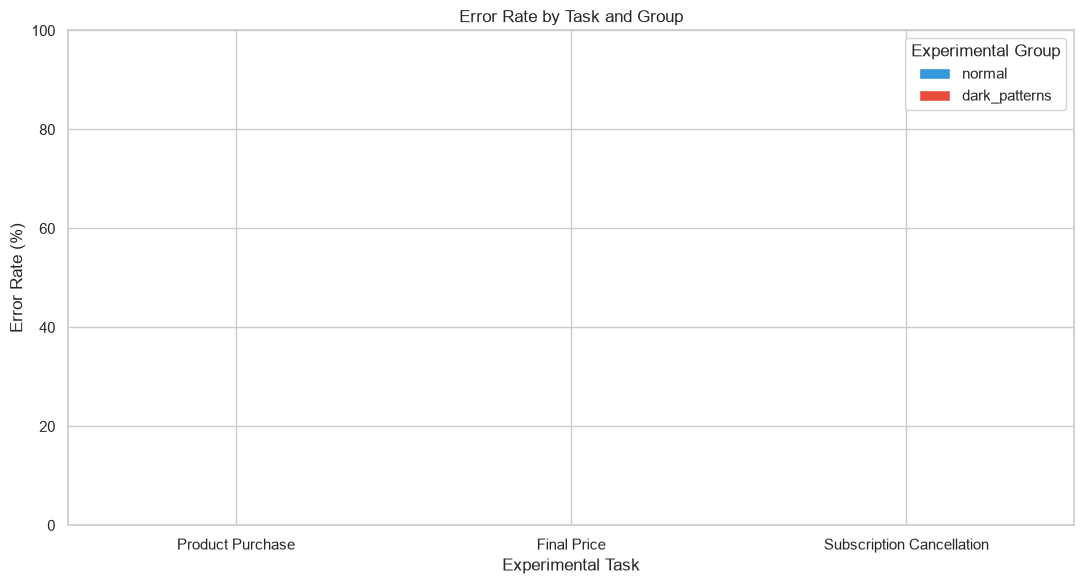

In [38]:
task_errors.plot(
    kind="bar",
    figsize=(11, 6),
    color=["#3498db", "#e74c3c"],
    rot=0
)

plt.title("Error Rate by Task and Group")
plt.xlabel("Experimental Task")
plt.ylabel("Error Rate (%)")
plt.ylim(0, 100)

plt.legend(title="Experimental Group")
plt.tight_layout()

plt.savefig(
    figures_folder / "task_error_rates.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [39]:
print("Grafice generate:\n")

for file in sorted(figures_folder.glob("*.png")):
    print(file.name)

print("\nNumar total de grafice:")
print(len(list(figures_folder.glob("*.png"))))

Grafice generate:

confidence.png
control.png
task_error_rates.png
total_clicks.png
total_errors.png
total_time.png

Numar total de grafice:
6


In [46]:
invalid_rows = df.loc[
    ~df.index.isin(df_clean.index)
]

print("Inregistrari eliminate:", len(invalid_rows))

display(invalid_rows.drop(columns=["participant_id"]))

Inregistrari eliminate: 15


,group,task1_time,task1_error,task1_clicks,task2_time,task2_error,task2_clicks,task3_time,task3_error,task3_clicks,total_time,total_errors,total_clicks,confidence,control
1,normal,"2,69",0,1,"5,17",0,2,"1,53",0,1,"9,39",0,4,4,5
2,dark_patterns,"2,43",1,1,"3,5",0,2,"2,98",0,1,"8,91",1,4,3,2
3,dark_patterns,"1,73",1,1,"3,28",0,2,"3,48",0,1,"8,49",1,4,2,2
4,normal,"1,71",0,1,"3,03",0,2,"2,4",0,1,"7,14",0,4,5,4
5,normal,"16,57",0,3,"9,4",0,2,"19,82",0,1,"45,79",0,6,4,4
6,normal,"18,32",1,2,"15,94",1,2,"4,6",0,1,"38,86",2,5,5,5
7,normal,"12,04",0,1,"19,29",0,3,"6,33",0,1,"37,66",0,5,2,1
8,dark_patterns,"5,86",1,1,"9,94",0,2,"4,1",1,1,"19,9",2,4,3,3
9,dark_patterns,"11,51",0,2,"10,96",0,2,"7,96",0,1,"30,43",0,5,4,3
10,normal,"10,72",1,2,"11,95",0,2,"4,2",0,1,"26,87",1,5,5,5
